# LLM-JEPA on NL-RX-Synth with Llama-3.2-1B-Instruct

Single-run comparison of plain fine-tuning (next-token prediction, NTP) against **LLM-JEPA**
(Huang et al., 2025) on NL-RX-Synth (natural-language description → regex).

$$\mathcal{L} = \mathcal{L}_{\text{NTP}}(\text{Text} \to \text{Code}) + \lambda \cdot \big(1 - \cos(\text{Pred}(\text{Enc}(\text{Text})), \text{Enc}(\text{Code}))\big)$$

- **Text view:** the description as a chat-formatted user message, followed by $k$ `[PRED]` tokens.
- **Code view:** the regex as a chat-formatted assistant message.
- **Enc / Pred:** last-layer hidden state of the last token, computed by the same LLM (tied-weights predictor).
- **Two forwards per step:** one for NTP and one packed sequence `[Text + PRED | Code]` with a block-causal
  4D attention mask, so that Code never attends to Text.

Setup: LoRA (r = 32) in bf16, one fixed 80/10/10 split, one run per method, exact-match accuracy on test.
This is a first signal, not a statistically robust comparison (no seed sweep, no grid over $(k, \lambda)$).

## 1. Configuration

In [1]:
import gc
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer, get_linear_schedule_with_warmup

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "datasets" / "raw" / "NL-RX-Synth"
OUT_DIR = ROOT / "outputs" / "llm_jepa_nlrx"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "meta-llama/Llama-3.2-1B-Instruct"
DATE_STRING = "26 Jul 2024"  # fixed date in the Llama chat template, so prompts do not change day to day

# One fixed split and one LoRA initialisation shared by both runs (not a seed sweep).
SEED = 0
SPLIT_FRACS = (0.8, 0.1, 0.1)

# LoRA
LORA_R = 32
LORA_ALPHA = 64
LORA_DROPOUT = 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

# Training
LR = 2e-5
BATCH_SIZE = 8
GRAD_ACCUM = 1  # effective batch size = BATCH_SIZE * GRAD_ACCUM
EPOCHS = 4
WARMUP_RATIO = 0.03
MAX_GRAD_NORM = 1.0
LOG_EVERY = 25
VAL_EVERY = 250

# LLM-JEPA (fixed in advance, no grid search)
JEPA_K = 1
JEPA_LAMBDA = 1.0

# Evaluation
EVAL_BATCH_SIZE = 64
MAX_NEW_TOKENS = 64

DEVICE = torch.device("cuda")
DTYPE = torch.bfloat16
print(torch.__version__, torch.cuda.get_device_name(0))
print("ROOT:", ROOT)

2.14.1+cu126 NVIDIA GeForce RTX 4070 SUPER
ROOT: /home/miguel/projects/jepa-llm


## 2. Data and split

In [2]:
src_lines = (DATA_DIR / "src.txt").read_text(encoding="utf-8").splitlines()
tgt_lines = (DATA_DIR / "targ.txt").read_text(encoding="utf-8").splitlines()
pairs = [(s.strip(), t.strip()) for s, t in zip(src_lines, tgt_lines)]
print(f"{len(src_lines)} descriptions, {len(tgt_lines)} regexes")
for s, t in pairs[:3]:
    print(f"  {s!r} -> {t!r}")

split_path = OUT_DIR / "split.json"
if split_path.exists():
    split = json.loads(split_path.read_text())
else:
    idx = list(range(len(pairs)))
    random.Random(SEED).shuffle(idx)
    n_train = int(SPLIT_FRACS[0] * len(idx))
    n_val = int(SPLIT_FRACS[1] * len(idx))
    split = {
        "train": sorted(idx[:n_train]),
        "val": sorted(idx[n_train : n_train + n_val]),
        "test": sorted(idx[n_train + n_val :]),
    }
    split_path.write_text(json.dumps(split))
print({k: len(v) for k, v in split.items()})

10000 descriptions, 10000 regexes
  'lines with words with a capital letter and a vowel' -> '\\b([A-Z])&([AEIOUaeiou])\\b'
  "lines ending with a character before the string 'dog'" -> '((.*)(.)).*(dog).*'
  'lines containing a letter or a character' -> '.*([A-Za-z])|(.).*'
{'train': 8000, 'val': 1000, 'test': 1000}


### Test: data integrity

In [3]:
assert len(src_lines) == len(tgt_lines), "src.txt and targ.txt must be parallel"
assert all(s and t for s, t in pairs), "no empty descriptions or regexes"
train_set, val_set, test_set = (set(split[k]) for k in ("train", "val", "test"))
assert not (train_set & val_set) and not (train_set & test_set) and not (val_set & test_set), "splits overlap"
assert len(train_set | val_set | test_set) == len(pairs), "split does not cover the dataset"

# Informational: identical (description, regex) pairs that appear in both train and test.
train_pairs = {pairs[i] for i in split["train"]}
dup = sum(pairs[i] in train_pairs for i in split["test"])
print(f"OK. Test examples whose exact pair also appears in train: {dup}/{len(split['test'])}")

OK. Test examples whose exact pair also appears in train: 16/1000


## 3. Tokenisation: NTP example, JEPA views and `[PRED]` tokens

In [4]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.pad_token = "<|finetune_right_pad_id|>"
PAD_ID = tok.pad_token_id
EOT_ID = tok.convert_tokens_to_ids("<|eot_id|>")
# [PRED] tokens: reserved special tokens already in the Llama 3 vocabulary (no resizing needed).
PRED_IDS = [tok.convert_tokens_to_ids(f"<|reserved_special_token_{i}|>") for i in range(8)]


def chat_ids(messages, add_generation_prompt=False):
    text = tok.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=add_generation_prompt, date_string=DATE_STRING
    )
    return tok(text, add_special_tokens=False).input_ids


def encode(desc, regex):
    prompt = chat_ids([{"role": "user", "content": desc}], add_generation_prompt=True)
    answer = tok(regex, add_special_tokens=False).input_ids + [EOT_ID]
    return {
        "prompt": prompt,                                   # used for generation
        "ntp_ids": prompt + answer,                         # NTP forward
        "ntp_labels": [-100] * len(prompt) + answer,        # loss only on the regex
        "text_view": chat_ids([{"role": "user", "content": desc}]),         # Text view (Enc input)
        "code_view": chat_ids([{"role": "assistant", "content": regex}]),   # Code view (target)
        "answer_len": len(answer),
        "desc": desc,
        "regex": regex,
    }


examples = [encode(s, t) for s, t in pairs]
train_ex = [examples[i] for i in split["train"]]
val_ex = [examples[i] for i in split["val"]]
test_ex = [examples[i] for i in split["test"]]

ex = train_ex[0]
print(repr(tok.decode(ex["ntp_ids"])))
print("text view:", repr(tok.decode(ex["text_view"])))
print("code view:", repr(tok.decode(ex["code_view"])))
lens = [len(e["ntp_ids"]) for e in examples]
print(f"NTP length: mean {sum(lens) / len(lens):.1f}, max {max(lens)}")

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


'<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n\nCutting Knowledge Date: December 2023\nToday Date: 26 Jul 2024\n\n<|eot_id|><|start_header_id|>user<|end_header_id|>\n\nlines with words with a capital letter and a vowel<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n\\b([A-Z])&([AEIOUaeiou])\\b<|eot_id|>'
text view: '<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n\nCutting Knowledge Date: December 2023\nToday Date: 26 Jul 2024\n\n<|eot_id|><|start_header_id|>user<|end_header_id|>\n\nlines with words with a capital letter and a vowel<|eot_id|>'
code view: '<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n\nCutting Knowledge Date: December 2023\nToday Date: 26 Jul 2024\n\n<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n\\b([A-Z])&([AEIOUaeiou])\\b<|eot_id|>'
NTP length: mean 64.2, max 86


## 4. Batching and the block-causal mask

The JEPA forward packs `[Text + k·PRED | Code]` into one sequence. The mask is causal inside each block and
blocks never attend to each other; position ids restart at 0 for Code, so each view is encoded exactly as if
it were alone. Padding rows attend only to themselves (avoids fully masked rows).

In [5]:
def ntp_batch(batch):
    L = max(len(e["ntp_ids"]) for e in batch)
    input_ids = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    labels = torch.full((len(batch), L), -100, dtype=torch.long)
    attn = torch.zeros((len(batch), L), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["ntp_ids"])
        input_ids[i, :n] = torch.tensor(e["ntp_ids"])
        labels[i, :n] = torch.tensor(e["ntp_labels"])
        attn[i, :n] = 1
    return {"input_ids": input_ids, "labels": labels, "attention_mask": attn}


def jepa_batch(batch, k):
    seqs, spans = [], []
    for e in batch:
        a = e["text_view"] + PRED_IDS[:k]
        b = e["code_view"]
        seqs.append(a + b)
        spans.append((len(a), len(b)))
    B, L = len(batch), max(len(s) for s in seqs)
    input_ids = torch.full((B, L), PAD_ID, dtype=torch.long)
    position_ids = torch.zeros((B, L), dtype=torch.long)
    allowed = torch.zeros((B, L, L), dtype=torch.bool)
    pred_idx, code_idx = [], []
    for i, (s, (la, lb)) in enumerate(zip(seqs, spans)):
        n = la + lb
        input_ids[i, :n] = torch.tensor(s)
        position_ids[i, :la] = torch.arange(la)
        position_ids[i, la:n] = torch.arange(lb)
        allowed[i, :la, :la] = torch.tril(torch.ones(la, la, dtype=torch.bool))
        allowed[i, la:n, la:n] = torch.tril(torch.ones(lb, lb, dtype=torch.bool))
        pad = torch.arange(n, L)
        allowed[i, pad, pad] = True
        pred_idx.append(la - 1)   # last [PRED] token (last Text token if k = 0)
        code_idx.append(n - 1)    # last Code token
    return {
        "input_ids": input_ids,
        "position_ids": position_ids,
        "allowed": allowed,
        "pred_idx": torch.tensor(pred_idx),
        "code_idx": torch.tensor(code_idx),
        "spans": spans,
    }


def additive_mask(allowed, dtype):
    mask = torch.zeros(allowed.shape[0], 1, *allowed.shape[1:], dtype=dtype)
    return mask.masked_fill(~allowed[:, None], torch.finfo(dtype).min)

### Test: mask structure and NTP labels

In [6]:
jb = jepa_batch(train_ex[:4], k=2)
for i, (la, lb) in enumerate(jb["spans"]):
    al = jb["allowed"][i]
    n = la + lb
    assert not al[la:n, :la].any(), "Code must not attend to Text or [PRED]"
    assert not al[:la, la:n].any(), "Text must not attend to Code"
    assert torch.equal(al[:la, :la], torch.tril(torch.ones(la, la, dtype=torch.bool))), "Text block must be causal"
    assert torch.equal(al[la:n, la:n], torch.tril(torch.ones(lb, lb, dtype=torch.bool))), "Code block must be causal"
    assert jb["position_ids"][i, la].item() == 0, "Code positions must restart at 0"
    assert jb["input_ids"][i, la - 1].item() == PRED_IDS[1], "last Text-side token must be the last [PRED]"

nb = ntp_batch(train_ex[:4])
for i, e in enumerate(train_ex[:4]):
    lab = nb["labels"][i]
    assert (lab != -100).sum().item() == e["answer_len"], "loss must count only the regex tokens (+ <|eot_id|>)"
    assert (lab[: len(e["prompt"])] == -100).all(), "prompt must be masked"
    assert (lab[nb["attention_mask"][i] == 0] == -100).all(), "padding must be masked"
print("OK")

OK


### Test: packed forward ≡ separate forwards

Done once in fp32 on the base model so the tolerance can be tight. If the custom 4D mask were ignored or
mishandled, `Enc(Code)` would see the Text block and this test would fail.

In [7]:
ref = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32).to(DEVICE).eval()
with torch.no_grad():
    jb = jepa_batch(train_ex[:4], k=JEPA_K)
    h = ref.model(
        input_ids=jb["input_ids"].to(DEVICE),
        position_ids=jb["position_ids"].to(DEVICE),
        attention_mask=additive_mask(jb["allowed"], torch.float32).to(DEVICE),
        use_cache=False,
    ).last_hidden_state
    for i, e in enumerate(train_ex[:4]):
        a = torch.tensor([e["text_view"] + PRED_IDS[:JEPA_K]], device=DEVICE)
        b = torch.tensor([e["code_view"]], device=DEVICE)
        ha = ref.model(input_ids=a, use_cache=False).last_hidden_state[0, -1]
        hb = ref.model(input_ids=b, use_cache=False).last_hidden_state[0, -1]
        torch.testing.assert_close(h[i, jb["pred_idx"][i]], ha, atol=1e-4, rtol=1e-4)
        torch.testing.assert_close(h[i, jb["code_idx"][i]], hb, atol=1e-4, rtol=1e-4)
    # Sanity check that the test can fail: without the block mask, Code would attend to Text.
    plain = ref.model(input_ids=jb["input_ids"][:1].to(DEVICE), use_cache=False).last_hidden_state
    leak = (plain[0, jb["code_idx"][0]] - h[0, jb["code_idx"][0]]).abs().max().item()
    assert leak > 1e-2, "a plain causal forward should differ from the packed one"
print(f"OK (max diff without the block mask: {leak:.3f})")
del ref
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

OK (max diff without the block mask: 3.522)


## 5. Model, losses and training loop

In [8]:
def build_model():
    base = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE).to(DEVICE)
    torch.manual_seed(SEED)  # identical LoRA initialisation for every run
    cfg = LoraConfig(
        r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
        target_modules=LORA_TARGETS, task_type="CAUSAL_LM",
    )
    return get_peft_model(base, cfg)


def jepa_distance(model, jb):
    # Same LLM as encoder and predictor; LoRA layers are active inside the backbone.
    backbone = model.get_base_model().model
    h = backbone(
        input_ids=jb["input_ids"].to(DEVICE),
        position_ids=jb["position_ids"].to(DEVICE),
        attention_mask=additive_mask(jb["allowed"], DTYPE).to(DEVICE),
        use_cache=False,
    ).last_hidden_state
    rows = torch.arange(h.shape[0], device=DEVICE)
    pred = h[rows, jb["pred_idx"].to(DEVICE)].float()
    target = h[rows, jb["code_idx"].to(DEVICE)].float()  # no stop-gradient, as in LLM-JEPA
    return (1 - F.cosine_similarity(pred, target, dim=-1)).mean()


def compute_losses(model, batch, lam, k):
    nb = {key: v.to(DEVICE) for key, v in ntp_batch(batch).items()}
    ntp = model(**nb, use_cache=False).loss
    jb = jepa_batch(batch, k)
    if lam > 0:
        dist = jepa_distance(model, jb)
        total = ntp + lam * dist
    else:
        with torch.no_grad():  # baseline: the distance is only logged
            dist = jepa_distance(model, jb)
        total = ntp
    return total, ntp.detach(), dist.detach()

### Test: with λ = 0 the loss is plain NTP cross-entropy

In [9]:
model = build_model()
model.eval()
batch = train_ex[:4]
with torch.no_grad():
    total, ntp, dist = compute_losses(model, batch, lam=0.0, k=JEPA_K)
    nb = {key: v.to(DEVICE) for key, v in ntp_batch(batch).items()}
    logits = model(input_ids=nb["input_ids"], attention_mask=nb["attention_mask"], use_cache=False).logits
    manual = F.cross_entropy(
        logits[:, :-1].float().reshape(-1, logits.shape[-1]), nb["labels"][:, 1:].reshape(-1), ignore_index=-100
    )
torch.testing.assert_close(total.float(), manual, atol=1e-2, rtol=1e-3)
print(f"OK: total {total.item():.4f} = manual CE {manual.item():.4f} (JEPA distance logged: {dist.item():.4f})")
del model, logits
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

OK: total 3.9942 = manual CE 3.9942 (JEPA distance logged: 0.6187)


In [10]:
@torch.no_grad()
def evaluate_losses(model, data, lam, k, bs=32):
    model.eval()
    ntps, dists = [], []
    for i in range(0, len(data), bs):
        _, ntp, dist = compute_losses(model, data[i : i + bs], lam=0.0, k=k)
        ntps.append(ntp.item())
        dists.append(dist.item())
    model.train()
    return sum(ntps) / len(ntps), sum(dists) / len(dists)


def train(tag, lam, k, data, epochs=EPOCHS, lr=LR, max_steps=None, val_data=None, log_every=LOG_EVERY):
    model = build_model()
    model.train()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    steps_per_epoch = math.ceil(len(data) / (BATCH_SIZE * GRAD_ACCUM))
    total_steps = max_steps or steps_per_epoch * epochs
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)
    rng = random.Random(SEED)
    hist = {"step": [], "ntp": [], "dist": [], "val_step": [], "val_ntp": [], "val_dist": []}
    step, t0 = 0, time.time()
    run_ntp, run_dist, run_n = 0.0, 0.0, 0
    while step < total_steps:
        order = list(range(len(data)))
        rng.shuffle(order)
        micro = [order[i : i + BATCH_SIZE] for i in range(0, len(order), BATCH_SIZE)]
        for j in range(0, len(micro), GRAD_ACCUM):
            for mb in micro[j : j + GRAD_ACCUM]:
                total, ntp, dist = compute_losses(model, [data[i] for i in mb], lam, k)
                (total / GRAD_ACCUM).backward()
                run_ntp, run_dist, run_n = run_ntp + ntp.item(), run_dist + dist.item(), run_n + 1
            torch.nn.utils.clip_grad_norm_(params, MAX_GRAD_NORM)
            opt.step()
            sched.step()
            opt.zero_grad(set_to_none=True)
            step += 1
            if step % log_every == 0 or step == total_steps:
                hist["step"].append(step)
                hist["ntp"].append(run_ntp / run_n)
                hist["dist"].append(run_dist / run_n)
                run_ntp, run_dist, run_n = 0.0, 0.0, 0
            if val_data is not None and (step % VAL_EVERY == 0 or step == total_steps):
                v_ntp, v_dist = evaluate_losses(model, val_data, lam, k)
                hist["val_step"].append(step)
                hist["val_ntp"].append(v_ntp)
                hist["val_dist"].append(v_dist)
                print(
                    f"[{tag}] step {step}/{total_steps}  train ntp {hist['ntp'][-1]:.4f}  "
                    f"train dist {hist['dist'][-1]:.4f}  val ntp {v_ntp:.4f}  val dist {v_dist:.4f}  "
                    f"({time.time() - t0:.0f}s)"
                )
            if step >= total_steps:
                break
    return model, hist

### Smoke test: 20 steps on 8 examples (higher LR so the drop is visible)

In [11]:
model, hist = train("smoke", lam=JEPA_LAMBDA, k=JEPA_K, data=train_ex[:8], lr=1e-4, max_steps=20, log_every=1)
assert all(math.isfinite(x) for x in hist["ntp"] + hist["dist"]), "NaN/inf in the losses"
assert hist["ntp"][-1] < hist["ntp"][0], "NTP loss should go down when overfitting 8 examples"
assert hist["dist"][-1] < hist["dist"][0], "JEPA distance should go down when it is optimised"
print(f"OK: ntp {hist['ntp'][0]:.3f} -> {hist['ntp'][-1]:.3f}, dist {hist['dist'][0]:.3f} -> {hist['dist'][-1]:.3f}")
del model
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

OK: ntp 3.872 -> 0.002, dist 0.641 -> 0.009


## 6. Evaluation: greedy decoding + exact match

In [12]:
@torch.no_grad()
def generate_predictions(model, data, bs=EVAL_BATCH_SIZE):
    model.eval()
    preds = []
    for i in range(0, len(data), bs):
        chunk = data[i : i + bs]
        L = max(len(e["prompt"]) for e in chunk)
        input_ids = torch.full((len(chunk), L), PAD_ID, dtype=torch.long)
        attn = torch.zeros((len(chunk), L), dtype=torch.long)
        for j, e in enumerate(chunk):  # left padding for generation
            n = len(e["prompt"])
            input_ids[j, L - n :] = torch.tensor(e["prompt"])
            attn[j, L - n :] = 1
        out = model.generate(
            input_ids=input_ids.to(DEVICE), attention_mask=attn.to(DEVICE),
            max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
            pad_token_id=PAD_ID, eos_token_id=EOT_ID,
        )
        preds += [s.strip() for s in tok.batch_decode(out[:, L:], skip_special_tokens=True)]
    return preds


def exact_match(preds, data):
    return sum(p == e["regex"] for p, e in zip(preds, data)) / len(data)


def run_and_evaluate(tag, lam, k):
    model, hist = train(tag, lam=lam, k=k, data=train_ex, val_data=val_ex)
    preds = generate_predictions(model, test_ex)
    acc = exact_match(preds, test_ex)
    run_dir = OUT_DIR / tag
    run_dir.mkdir(exist_ok=True)
    model.save_pretrained(run_dir / "adapter")
    (run_dir / "history.json").write_text(json.dumps(hist))
    with open(run_dir / "test_predictions.jsonl", "w") as f:
        for p, e in zip(preds, test_ex):
            f.write(json.dumps({"desc": e["desc"], "gold": e["regex"], "pred": p, "correct": p == e["regex"]}) + "\n")
    print(f"[{tag}] test exact match: {acc:.4f}")
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return {"tag": tag, "lambda": lam, "k": k, "test_exact_match": acc, "hist": hist}

## 7. Runs: baseline (λ = 0) and LLM-JEPA

In [13]:
baseline = run_and_evaluate("baseline", lam=0.0, k=JEPA_K)

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[baseline] step 250/4000  train ntp 0.2406  train dist 0.4718  val ntp 0.2401  val dist 0.4756  (64s)


[baseline] step 500/4000  train ntp 0.1281  train dist 0.4711  val ntp 0.1158  val dist 0.4732  (125s)


[baseline] step 750/4000  train ntp 0.1014  train dist 0.4873  val ntp 0.0813  val dist 0.4834  (186s)


[baseline] step 1000/4000  train ntp 0.0682  train dist 0.4702  val ntp 0.0611  val dist 0.4786  (248s)


[baseline] step 1250/4000  train ntp 0.0564  train dist 0.4785  val ntp 0.0571  val dist 0.4772  (309s)


... (8 outputs left out)

[baseline] step 3500/4000  train ntp 0.0169  train dist 0.4638  val ntp 0.0287  val dist 0.4702  (865s)


[baseline] step 3750/4000  train ntp 0.0173  train dist 0.4717  val ntp 0.0278  val dist 0.4681  (927s)


[baseline] step 4000/4000  train ntp 0.0130  train dist 0.4656  val ntp 0.0264  val dist 0.4702  (994s)


[baseline] test exact match: 0.8680


In [14]:
llm_jepa = run_and_evaluate("llm_jepa", lam=JEPA_LAMBDA, k=JEPA_K)

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[llm_jepa] step 250/4000  train ntp 0.2431  train dist 0.0046  val ntp 0.2417  val dist 0.0042  (83s)


[llm_jepa] step 500/4000  train ntp 0.1287  train dist 0.0017  val ntp 0.1201  val dist 0.0016  (179s)


[llm_jepa] step 750/4000  train ntp 0.0955  train dist 0.0010  val ntp 0.0779  val dist 0.0009  (271s)


[llm_jepa] step 1000/4000  train ntp 0.0694  train dist 0.0006  val ntp 0.0630  val dist 0.0006  (356s)


[llm_jepa] step 1250/4000  train ntp 0.0518  train dist 0.0005  val ntp 0.0597  val dist 0.0004  (443s)


... (8 outputs left out)

[llm_jepa] step 3500/4000  train ntp 0.0174  train dist 0.0002  val ntp 0.0297  val dist 0.0001  (1323s)


[llm_jepa] step 3750/4000  train ntp 0.0181  train dist 0.0002  val ntp 0.0282  val dist 0.0001  (1432s)


[llm_jepa] step 4000/4000  train ntp 0.0126  train dist 0.0002  val ntp 0.0274  val dist 0.0001  (1519s)


[llm_jepa] test exact match: 0.8740


## 8. Results

In [15]:
results = [baseline, llm_jepa]
summary = [{k: r[k] for k in ("tag", "lambda", "k", "test_exact_match")} for r in results]
(OUT_DIR / "results.json").write_text(json.dumps(summary, indent=2))

print("| Run | λ | k | Test exact match |")
print("|---|---|---|---|")
for r in summary:
    print(f"| {r['tag']} | {r['lambda']} | {r['k']} | {100 * r['test_exact_match']:.2f} % |")
print(f"\nn_test = {len(test_ex)}; one run per method (no seeds, no CI).")

| Run | λ | k | Test exact match |
|---|---|---|---|
| baseline | 0.0 | 1 | 86.80 % |
| llm_jepa | 1.0 | 1 | 87.40 % |

n_test = 1000; one run per method (no seeds, no CI).


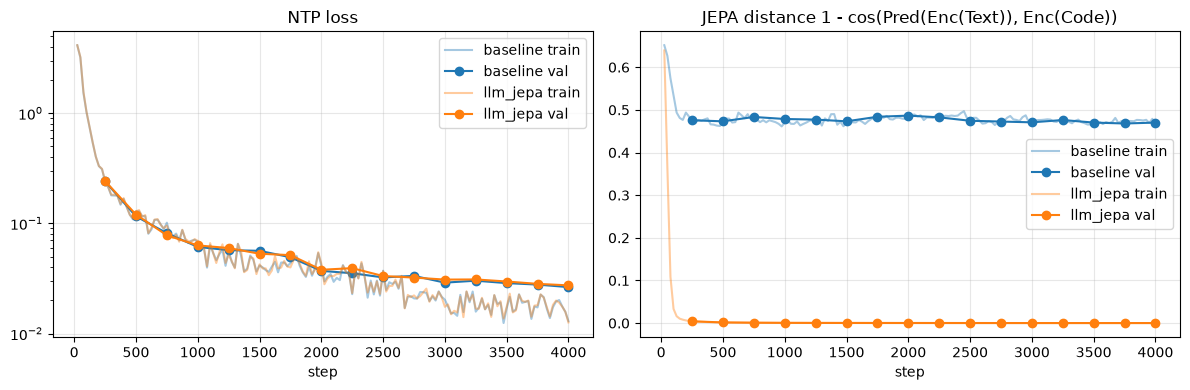

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for r, color in zip(results, ["tab:blue", "tab:orange"]):
    h = r["hist"]
    axes[0].plot(h["step"], h["ntp"], color=color, alpha=0.4, label=f"{r['tag']} train")
    axes[0].plot(h["val_step"], h["val_ntp"], color=color, marker="o", label=f"{r['tag']} val")
    axes[1].plot(h["step"], h["dist"], color=color, alpha=0.4, label=f"{r['tag']} train")
    axes[1].plot(h["val_step"], h["val_dist"], color=color, marker="o", label=f"{r['tag']} val")
axes[0].set(title="NTP loss", xlabel="step", yscale="log")
axes[1].set(title="JEPA distance 1 - cos(Pred(Enc(Text)), Enc(Code))", xlabel="step")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "curves.png", dpi=120)
plt.show()

**Reading the result.** The paper reports 57.29 ± 5.32 (baseline) vs. 71.46 ± 1.34 (LLM-JEPA) for
Llama-3.2-1B on NL-RX-Synth, with full fine-tuning, its own split and the best $(k, \lambda)$ of a 20-point grid.
Here there is one run per method, LoRA, a different split and a fixed $(k, \lambda)$, so the numbers are not
directly comparable and a gap of a few points can be noise.